# Activité Pratique : Bases de PyTorch
## Résolution des 4 Exercices

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import os

# Fixer la graine aléatoire pour garantir la reproductibilité des résultats
torch.manual_seed(42)
np.random.seed(42)

# Configuration de l'appareil d'exécution (GPU CUDA si disponible, sinon CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Version de PyTorch : {torch.__version__}")
print(f"Appareil d'exécution utilisé : {device}")


Version de PyTorch : 2.14.1+cpu
Appareil d'exécution utilisé : cpu


---
# Exercice 1 : Régression linéaire multiple
### Prédire le salaire selon l'ancienneté et le niveau d'expertise



In [2]:
# 1. Génération des données synthétiques
torch.manual_seed(42)

# Nombre de salariés
n = 300

# Ancienneté : de 0 à 20 ans
anciennete = torch.randint(0, 21, (n, 1)).float()

# Expertise : note de 1 à 5
expertise = torch.randint(1, 6, (n, 1)).float()

# Variations aléatoires des salaires (bruit gaussien d'écart-type 500 DH)
bruit = torch.randn(n, 1) * 500

# Salaire mensuel en DH
salaires = (
    4000
    + 600 * anciennete
    + 1500 * expertise
    + bruit
)

# Matrice des entrées : dimensions (300, 2)
X = torch.cat([anciennete, expertise], dim=1)

# Sortie cible : dimensions (300, 1)
y = salaires

# Travail demandé : affichage des dimensions et du salaire moyen
print(f"Dimensions de la matrice X : {X.shape}")
print(f"Dimensions de la sortie y   : {y.shape}")
print(f"Salaire moyen              : {y.mean().item():.2f} DH")
print(f"Salaire minimum            : {y.min().item():.2f} DH")
print(f"Salaire maximum            : {y.max().item():.2f} DH\n")

print("Aperçu des 5 premiers profils générés :")
for i in range(5):
    print(
        f"  Salarié {i+1} : Ancienneté = {X[i, 0].item():2.0f} ans | "
        f"Expertise = {X[i, 1].item():.0f}/5 | "
        f"Salaire = {y[i, 0].item():.2f} DH"
    )


Dimensions de la matrice X : torch.Size([300, 2])
Dimensions de la sortie y   : torch.Size([300, 1])
Salaire moyen              : 15010.55 DH
Salaire minimum            : 5361.67 DH
Salaire maximum            : 23725.63 DH

Aperçu des 5 premiers profils générés :
  Salarié 1 : Ancienneté = 15 ans | Expertise = 2/5 | Salaire = 16262.90 DH
  Salarié 2 : Ancienneté =  2 ans | Expertise = 3/5 | Salaire = 10541.39 DH
  Salarié 3 : Ancienneté =  4 ans | Expertise = 3/5 | Salaire = 10948.37 DH
  Salarié 4 : Ancienneté = 19 ans | Expertise = 3/5 | Salaire = 20028.54 DH
  Salarié 5 : Ancienneté = 18 ans | Expertise = 2/5 | Salaire = 18036.38 DH


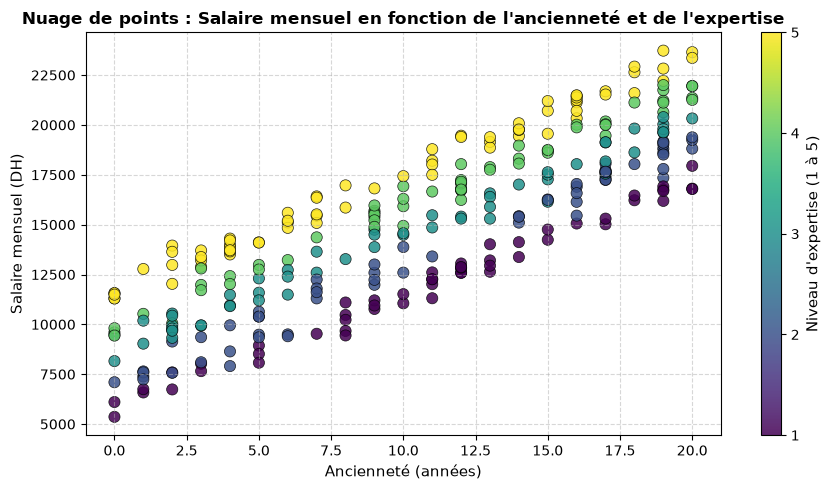

In [3]:
# Visualisation : nuage de points du salaire selon l'ancienneté, coloré par l'expertise
plt.figure(figsize=(9, 5))
scatter = plt.scatter(
    X[:, 0].numpy(),
    y[:, 0].numpy(),
    c=X[:, 1].numpy(),
    cmap="viridis",
    s=65,
    alpha=0.85,
    edgecolors="k",
    linewidths=0.5
)
cbar = plt.colorbar(scatter)
cbar.set_label("Niveau d'expertise (1 à 5)", fontsize=11)
cbar.set_ticks([1, 2, 3, 4, 5])

plt.title("Nuage de points : Salaire mensuel en fonction de l'ancienneté et de l'expertise", fontsize=12, fontweight="bold")
plt.xlabel("Ancienneté (années)", fontsize=11)
plt.ylabel("Salaire mensuel (DH)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### 2. Séparer et préparer les données
- 80 % des données sont réservées pour l'entraînement ($240$ exemples) et 20 % pour le test ($60$ exemples).
- Standardisation des entrées ($X$) à partir des statistiques de moyenne et d'écart-type calculées **uniquement sur le jeu d'entraînement** pour éviter toute fuite d'information (*data leakage*).
- Expression des salaires cibles en milliers de DH ($y / 1000$) afin d'aligner l'ordre de grandeur de la perte et de stabiliser l'apprentissage.


In [4]:
# Séparation 80% entraînement, 20% test
n = len(X)
indices = torch.randperm(n)
limite = int(0.8 * n)

train_indices = indices[:limite]
test_indices = indices[limite:]

X_train = X[train_indices]
X_test = X[test_indices]

# Salaires exprimés en milliers de DH
y_train = y[train_indices] / 1000
y_test = y[test_indices] / 1000

# Statistiques calculées UNIQUEMENT sur le jeu d'entraînement
moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)

# Standardisation des caractéristiques
X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

print(f"Taille du jeu d'entraînement : {X_train_norm.shape[0]} salariés")
print(f"Taille du jeu de test         : {X_test_norm.shape[0]} salariés")
print(f"Moyennes calculées (Train)    : Ancienneté = {moyenne[0, 0].item():.2f} ans, Expertise = {moyenne[0, 1].item():.2f}")
print(f"Écarts-types calculés (Train) : Ancienneté = {ecart_type[0, 0].item():.2f}, Expertise = {ecart_type[0, 1].item():.2f}")


Taille du jeu d'entraînement : 240 salariés
Taille du jeu de test         : 60 salariés
Moyennes calculées (Train)    : Ancienneté = 10.54 ans, Expertise = 3.15
Écarts-types calculés (Train) : Ancienneté = 6.12, Expertise = 1.44


### 3. Construire et entraîner le modèle
- Modèle linéaire : 2 entrées (ancienneté normalisée, expertise normalisée) et 1 sortie (salaire prédit en kDH).
- Critère de perte : `nn.MSELoss()` (Erreur Quadratique Moyenne).
- Optimiseur : Descente de Gradient Stochastique (`torch.optim.SGD`) avec un taux d'apprentissage de $0.05$.
- Boucle d'entraînement sur 500 époques sur l'ensemble du jeu d'entraînement (batch gradient descent).


In [5]:
# Deux variables d'entrée et une sortie scalaire
model1 = nn.Linear(in_features=2, out_features=1)

# Fonction de coût : Erreur quadratique moyenne (MSE)
criterion1 = nn.MSELoss()

# Optimiseur SGD avec un taux d'apprentissage de 0.05
optimizer1 = torch.optim.SGD(model1.parameters(), lr=0.05)

historique1 = []

model1.train()

for epoch in range(500):
    # 1. Réinitialiser les gradients accumulés
    optimizer1.zero_grad()

    # 2. Prédire les salaires (en milliers de DH)
    predictions = model1(X_train_norm)

    # 3. Calculer la perte MSE
    loss = criterion1(predictions, y_train)

    # 4. Calculer les gradients par rétropropagation (backpropagation)
    loss.backward()

    # 5. Mettre à jour les paramètres (poids et biais)
    optimizer1.step()

    # Enregistrer la perte
    historique1.append(loss.item())

    # Affichage régulier de la progression
    if (epoch + 1) % 100 == 0:
        print(f"Époque {epoch + 1:3d}/500 | Perte (MSE) : {loss.item():.4f}")


Époque 100/500 | Perte (MSE) : 0.2391
Époque 200/500 | Perte (MSE) : 0.2391
Époque 300/500 | Perte (MSE) : 0.2391
Époque 400/500 | Perte (MSE) : 0.2391
Époque 500/500 | Perte (MSE) : 0.2391


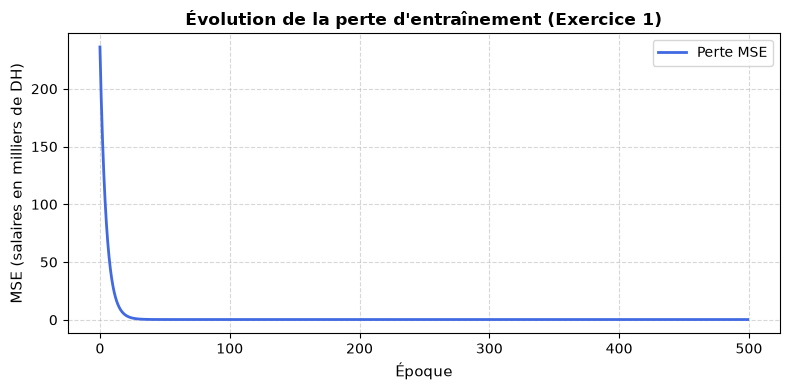

In [6]:
# Tracé de l'évolution de la perte d'entraînement
plt.figure(figsize=(8, 4))
plt.plot(historique1, color="royalblue", linewidth=2, label="Perte MSE")
plt.xlabel("Époque", fontsize=11)
plt.ylabel("MSE (salaires en milliers de DH)", fontsize=11)
plt.title("Évolution de la perte d'entraînement (Exercice 1)", fontsize=12, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


### 4. Évaluer les prédictions
Évaluation sur le jeu de test non vu lors de l'apprentissage avec l'Erreur Absolue Moyenne (**MAE** en DH) :
$$\text{MAE} = \frac{1}{N_{\text{test}}} \sum_{i=1}^{N_{\text{test}}} |\hat{y}_i - y_i|$$


In [7]:
model1.eval()

with torch.no_grad():
    predictions_test = model1(X_test_norm)

    # Conversion en DH (multiplication par 1000)
    predictions_dh = predictions_test * 1000
    salaires_reels_dh = y_test * 1000

    # Calcul de l'erreur absolue moyenne (MAE)
    mae = torch.mean(torch.abs(predictions_dh - salaires_reels_dh))

print(f"Erreur absolue moyenne (MAE) sur le test : {mae.item():.2f} DH")


Erreur absolue moyenne (MAE) sur le test : 381.64 DH


### 5. Prédire le salaire d’un nouveau salarié
Prédire le salaire d’une personne ayant :
- 7 ans d’ancienneté ;
- un niveau d’expertise de 4/5.

**Valeur théorique attendue (sans bruit) :**
$$4000 + 600 \times 7 + 1500 \times 4 = 14\,200 \text{ DH}$$


In [8]:
nouveau_salarie = torch.tensor([[7.0, 4.0]])

# Appliquer la même normalisation que sur le jeu d'entraînement
nouveau_salarie_norm = (nouveau_salarie - moyenne) / ecart_type

with torch.no_grad():
    # Prédiction du modèle et conversion en DH
    salaire_predit = model1(nouveau_salarie_norm) * 1000

valeur_theorique = 4000 + 600 * 7 + 1500 * 4
print(f"Salaire estimé par le modèle : {salaire_predit.item():.2f} DH")
print(f"Salaire théorique sans bruit : {valeur_theorique:.2f} DH")
print(f"Écart absolu                 : {abs(salaire_predit.item() - valeur_theorique):.2f} DH")


Salaire estimé par le modèle : 14201.94 DH
Salaire théorique sans bruit : 14200.00 DH
Écart absolu                 : 1.94 DH


### 6. Réponses détaillées aux questions complémentaires

1. **À expertise constante, quel est l’effet d’une année d’ancienneté supplémentaire ?**
   - L'effet marginal d'une année d'expérience est représenté par la dérivée partielle par rapport à l'ancienneté, c'est-à-dire le coefficient $w_1 = 600$ DH. À niveau d'expertise identique, chaque année d'ancienneté supplémentaire augmente le salaire mensuel moyen de **600 DH**.

2. **Pourquoi la perte ne devient-elle pas exactement nulle ?**
   - Le processus générateur de données comporte un terme de bruit aléatoire gaussien non nul : $\text{Bruit} \sim \mathcal{N}(0, 500^2)$. Ce bruit représente l'erreur irréductible due à des facteurs individuels non mesurés. Aucun modèle purement déterministe ne peut prédire un aléa indépendant ; la perte minimale théorique atteignable correspond donc à la variance du bruit (en unités normalisées, environ $(500/1000)^2 = 0.25$ kDH$^2$).

3. **Le modèle est-il fiable pour une ancienneté de 40 ans, absente des données d’entraînement ?**
   - **Non**, le modèle n'est pas fiable pour $40$ ans d'expérience. Les données d'entraînement couvrent l'intervalle $[0, 20]$ ans. Une prédiction à $40$ ans constitue une **extrapolation hors du domaine de validité**. Rien ne garantit que la progression salariale reste strictement linéaire (phénomènes de plafonnement des carrières, seuils hiérarchiques, âge légal de départ à la retraite, etc.).

4. **Quel effet aurait une augmentation du bruit sur la précision ?**
   - Une hausse de l'écart-type du bruit ($\sigma > 500$ DH) élargirait la dispersion des salaires autour de la droite de régression. Par conséquent, l'erreur quadratique (MSE) et l'erreur absolue moyenne (MAE) augmenteraient proportionnellement, entraînant une baisse de précision des prédictions individuelles sans pour autant biaiser l'estimation des coefficients moyens si le bruit reste centré.

5. **Retrouver les coefficients en unités d’origine à partir des paramètres du modèle entraîné :**
   - Le modèle prédictif en coordonnées standardisées s'écrit :
     $$\hat{y}_{\text{norm}} = w_1^{\text{norm}} \cdot \left(\frac{x_1 - \mu_1}{\sigma_1}\right) + w_2^{\text{norm}} \cdot \left(\frac{x_2 - \mu_2}{\sigma_2}\right) + b^{\text{norm}}$$
   - Pour obtenir la prédiction en Dirhams réels (sachant que $y = 1000 \cdot y_{\text{norm}}$) :
     $$\hat{y}_{\text{DH}} = \left(\frac{1000 \cdot w_1^{\text{norm}}}{\sigma_1}\right) x_1 + \left(\frac{1000 \cdot w_2^{\text{norm}}}{\sigma_2}\right) x_2 + 1000 \cdot \left( b^{\text{norm}} - \frac{w_1^{\text{norm}} \mu_1}{\sigma_1} - \frac{w_2^{\text{norm}} \mu_2}{\sigma_2} \right)$$
   - On en déduit directement les coefficients dé-normalisés :
     $$w_1^{\text{orig}} = \frac{1000 \cdot w_1^{\text{norm}}}{\sigma_1}, \quad w_2^{\text{orig}} = \frac{1000 \cdot w_2^{\text{norm}}}{\sigma_2}, \quad b^{\text{orig}} = 1000 \cdot \left( b^{\text{norm}} - \sum_{j=1}^2 \frac{w_j^{\text{norm}} \mu_j}{\sigma_j} \right)$$


In [9]:
# Extraction des paramètres du modèle entraîné
w_norm = model1.weight.data[0]   # tenseur de taille 2 : [w1_norm, w2_norm]
b_norm = model1.bias.data[0]     # scalaire : b_norm

mu = moyenne[0]
std = ecart_type[0]

# Calcul des coefficients en unités d'origine (DH)
w1_retrouve = (1000.0 * w_norm[0] / std[0]).item()
w2_retrouve = (1000.0 * w_norm[1] / std[1]).item()
b_retrouve  = (1000.0 * (b_norm - (w_norm[0] * mu[0] / std[0]) - (w_norm[1] * mu[1] / std[1]))).item()

print("Comparaison des coefficients retrouvés vs valeurs cibles théoriques :")
print(f"  w1 (Ancienneté) : estimé = {w1_retrouve:6.1f} DH/an  | valeur cible =  600.0 DH/an")
print(f"  w2 (Expertise)  : estimé = {w2_retrouve:6.1f} DH/note | valeur cible = 1500.0 DH/note")
print(f"  b  (Biais)      : estimé = {b_retrouve:6.1f} DH      | valeur cible = 4000.0 DH")


Comparaison des coefficients retrouvés vs valeurs cibles théoriques :
  w1 (Ancienneté) : estimé =  592.7 DH/an  | valeur cible =  600.0 DH/an
  w2 (Expertise)  : estimé = 1490.7 DH/note | valeur cible = 1500.0 DH/note
  b  (Biais)      : estimé = 4090.3 DH      | valeur cible = 4000.0 DH


---
# Exercice 2 : Classifier les chiffres MNIST avec un MLP
### Réseau de neurones dense (Multi-Layer Perceptron), mini-lots et évaluation complète


In [10]:
# Chargement des données MNIST avec transformation en tenseur
transform_mlp = transforms.ToTensor()

train_dataset_mlp = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform_mlp
)

test_dataset_mlp = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform_mlp
)

# Création des DataLoaders : mini-lots de 64 pour train, 256 pour test
train_loader_mlp = DataLoader(train_dataset_mlp, batch_size=64, shuffle=True)
test_loader_mlp  = DataLoader(test_dataset_mlp, batch_size=256, shuffle=False)

print(f"Nombre d'images d'entraînement : {len(train_dataset_mlp)}")
print(f"Nombre d'images de test         : {len(test_dataset_mlp)}")
print(f"Nombre de mini-lots (train)     : {len(train_loader_mlp)} (lots de 64 images)")
print(f"Nombre de mini-lots (test)      : {len(test_loader_mlp)} (lots de 256 images)")


Nombre d'images d'entraînement : 60000
Nombre d'images de test         : 10000
Nombre de mini-lots (train)     : 938 (lots de 64 images)
Nombre de mini-lots (test)      : 40 (lots de 256 images)


### Définition du modèle MLP
Le réseau prend en entrée des images 2D de taille $28 \times 28$ pixels :
1. `nn.Flatten()` : aplatit chaque image en un vecteur 1D de dimension $28 \times 28 = 784$.
2. `nn.Linear(784, 128)` : couche dense cachée projetant de 784 à 128 neurones.
3. `nn.ReLU()` : fonction d'activation non linéaire.
4. `nn.Linear(128, 10)` : couche de sortie produisant les 10 scores bruts (*logits*), un par chiffre (0 à 9).

*Remarque importante :* `nn.CrossEntropyLoss` applique en interne un `LogSoftmax` suivi du `NLLLoss` (Negative Log-Likelihood), il ne faut donc **pas** ajouter de Softmax à la sortie du modèle.


In [11]:
# Architecture du modèle MLP
model_mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)

# Fonction de perte et optimiseur
criterion_mlp = nn.CrossEntropyLoss()
optimizer_mlp = torch.optim.Adam(model_mlp.parameters(), lr=0.001)

print("Architecture du modèle MLP :")
print(model_mlp)


Architecture du modèle MLP :
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)


### Entraînement du modèle pendant 5 époques
À chaque époque, nous parcourons tous les mini-lots d'entraînement en activant le mode `model.train()`.


In [12]:
# Entraînement pendant 5 époques
epochs_mlp = 5
history_mlp_loss = []

for epoch in range(epochs_mlp):
    model_mlp.train()  # Activer le mode entraînement
    total_loss = 0.0

    for images, labels in train_loader_mlp:
        images = images.to(device)
        labels = labels.to(device)

        # 1. Remise à zéro des gradients
        optimizer_mlp.zero_grad()

        # 2. Propagation avant (forward pass)
        outputs = model_mlp(images)

        # 3. Calcul de la perte
        loss = criterion_mlp(outputs, labels)

        # 4. Rétropropagation (backward pass)
        loss.backward()

        # 5. Mise à jour des poids
        optimizer_mlp.step()

        total_loss += loss.item() * images.size(0)

    loss_moyenne = total_loss / len(train_dataset_mlp)
    history_mlp_loss.append(loss_moyenne)
    print(f"Époque {epoch + 1}/{epochs_mlp} | Perte moyenne : {loss_moyenne:.4f}")


Époque 1/5 | Perte moyenne : 0.3497
Époque 2/5 | Perte moyenne : 0.1569
Époque 3/5 | Perte moyenne : 0.1092
Époque 4/5 | Perte moyenne : 0.0831
Époque 5/5 | Perte moyenne : 0.0659


### Évaluation sur le jeu de test et calcul des métriques
- Activation de `model.eval()` et du contexte sans gradient `torch.no_grad()` pour désactiver le calcul de l'autograd et accélérer l'inférence.
- Prédiction de classe : `predicted_classes = outputs.argmax(dim=1)`.
- Calcul de l'**Accuracy**, de la **Précision**, du **Rappel** (*Recall*) et du **F1-Score** avec `classification_report`.


In [13]:
# Évaluation sur le jeu de test
model_mlp.eval()

toutes_predictions = []
toutes_vraies_classes = []

with torch.no_grad():
    for images, labels in test_loader_mlp:
        images = images.to(device)
        labels = labels.to(device)

        # Calcul des logits
        outputs = model_mlp(images)

        # Obtenir les classes prédites (indice du score maximal)
        predicted_classes = outputs.argmax(dim=1)

        toutes_predictions.extend(predicted_classes.cpu().numpy())
        toutes_vraies_classes.extend(labels.cpu().numpy())

toutes_predictions = np.array(toutes_predictions)
toutes_vraies_classes = np.array(toutes_vraies_classes)

# Calcul global de l'accuracy
accuracy_mlp = np.mean(toutes_predictions == toutes_vraies_classes)
print(f"Accuracy sur l'ensemble de test : {accuracy_mlp:.2%}\n")

# Rapport détaillé de classification (Précision, Rappel, F1-Score par classe)
rapport = classification_report(
    toutes_vraies_classes,
    toutes_predictions,
    target_names=[f"Chiffre {i}" for i in range(10)],
    digits=4
)
print("Rapport de classification complet (Accuracy, Précision, Rappel, F1-Score) :")
print(rapport)


Accuracy sur l'ensemble de test : 97.36%

Rapport de classification complet (Accuracy, Précision, Rappel, F1-Score) :
              precision    recall  f1-score   support

   Chiffre 0     0.9729    0.9888    0.9808       980
   Chiffre 1     0.9876    0.9859    0.9868      1135
   Chiffre 2     0.9692    0.9758    0.9725      1032
   Chiffre 3     0.9529    0.9822    0.9673      1010
   Chiffre 4     0.9886    0.9705    0.9794       982
   Chiffre 5     0.9917    0.9428    0.9667       892
   Chiffre 6     0.9718    0.9718    0.9718       958
   Chiffre 7     0.9737    0.9708    0.9722      1028
   Chiffre 8     0.9642    0.9692    0.9667       974
   Chiffre 9     0.9656    0.9732    0.9694      1009

    accuracy                         0.9736     10000
   macro avg     0.9738    0.9731    0.9734     10000
weighted avg     0.9738    0.9736    0.9736     10000



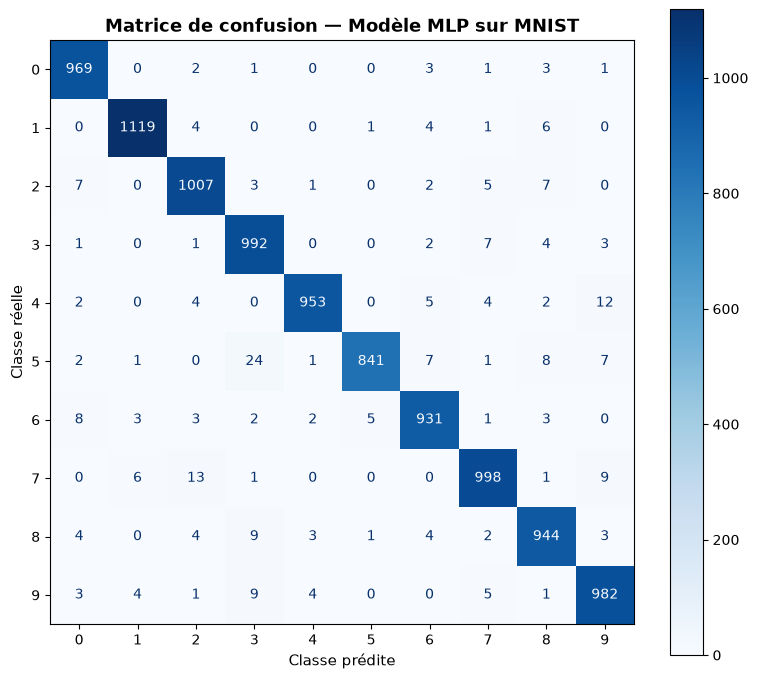

In [14]:
# Affichage de la matrice de confusion
cm_mlp = confusion_matrix(toutes_vraies_classes, toutes_predictions)

fig, ax = plt.subplots(figsize=(8, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_mlp, display_labels=list(range(10)))
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=True)
plt.title("Matrice de confusion — Modèle MLP sur MNIST", fontsize=13, fontweight="bold")
plt.xlabel("Classe prédite", fontsize=11)
plt.ylabel("Classe réelle", fontsize=11)
plt.grid(False)
plt.tight_layout()
plt.show()


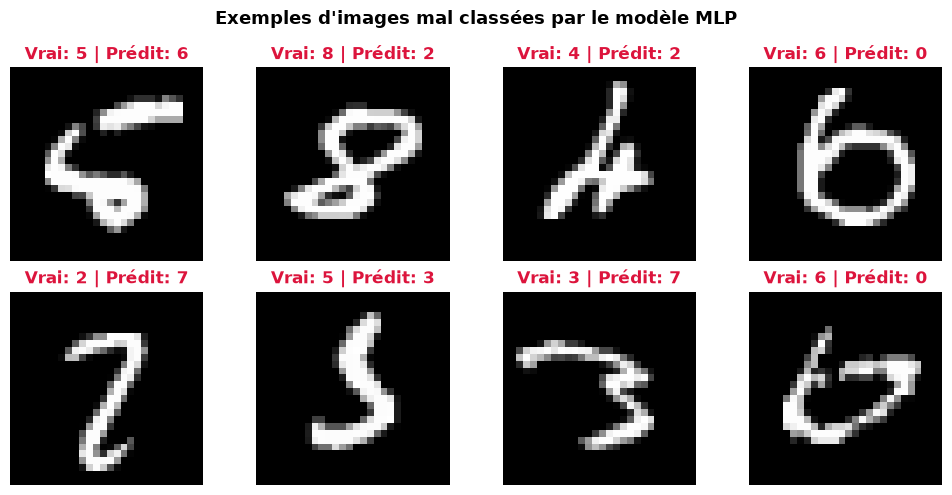

In [15]:
# Recherche et affichage de quelques images mal classées
model_mlp.eval()
images_mal_classees = []
vraies_classes_err = []
pred_classes_err = []

with torch.no_grad():
    for images, labels in test_loader_mlp:
        images_dev = images.to(device)
        outputs = model_mlp(images_dev)
        preds = outputs.argmax(dim=1).cpu()
        
        masque_erreurs = (preds != labels)
        if masque_erreurs.any():
            for img, vraie, pred in zip(images[masque_erreurs], labels[masque_erreurs], preds[masque_erreurs]):
                images_mal_classees.append(img.squeeze())
                vraies_classes_err.append(vraie.item())
                pred_classes_err.append(pred.item())
                if len(images_mal_classees) >= 8:
                    break
        if len(images_mal_classees) >= 8:
            break

# Affichage sous forme de grille
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images_mal_classees[i], cmap="gray")
    ax.set_title(f"Vrai: {vraies_classes_err[i]} | Prédit: {pred_classes_err[i]}", color="crimson", fontweight="bold")
    ax.axis("off")

plt.suptitle("Exemples d'images mal classées par le modèle MLP", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


### Sauvegarder et recharger un modèle
Pour réutiliser un réseau sans recommencer l'apprentissage :
- Sauvegarde du dictionnaire des paramètres avec `torch.save(model.state_dict(), chemin)`.
- Rechargement dans une nouvelle instance vierge de même architecture avec `model.load_state_dict(torch.load(chemin))`.


In [16]:
# 1. Sauvegarder les poids du modèle
chemin_mlp = "mnist_mlp.pth"
torch.save(model_mlp.state_dict(), chemin_mlp)
print(f"Modèle MLP sauvegardé dans : {chemin_mlp}")

# 2. Instancier un modèle vierge de même architecture
modele_recharge = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)

# 3. Charger les paramètres sauvegardés
modele_recharge.load_state_dict(torch.load(chemin_mlp, weights_only=True))
modele_recharge.eval()
print("Modèle rechargé avec succès !")

# 4. Vérification que les prédictions sont 100% identiques
images_test_lot, labels_test_lot = next(iter(test_loader_mlp))
images_test_lot = images_test_lot.to(device)

with torch.no_grad():
    pred_original = model_mlp(images_test_lot).argmax(dim=1)
    pred_recharge = modele_recharge(images_test_lot).argmax(dim=1)

sont_identiques = torch.equal(pred_original, pred_recharge)
print(f"Vérification d'invariance des prédictions : {'SUCCÈS (Strictement identiques)' if sont_identiques else 'ÉCHEC'}")


Modèle MLP sauvegardé dans : mnist_mlp.pth
Modèle rechargé avec succès !
Vérification d'invariance des prédictions : SUCCÈS (Strictement identiques)


---
# Exercice 3 — Classification des fleurs Iris 🌸

**Objectif :**
Entraîner un réseau de neurones pour prédire l’espèce d’une fleur d'Iris à partir de quatre mesures morphologiques :
1. Longueur des sépales (*sepal length*) ;
2. Largeur des sépales (*sepal width*) ;
3. Longueur des pétales (*petal length*) ;
4. Largeur des pétales (*petal width*).

Le jeu de données Iris contient **150 fleurs** réparties équitablement en **trois classes** ($50$ par classe) :
- Classe $0$ : *Iris setosa*
- Classe $1$ : *Iris versicolor*
- Classe $2$ : *Iris virginica*


In [17]:
# 1. Chargement et préparation des données Iris
torch.manual_seed(42)

# Charger le dataset
iris = load_iris()
X_iris, y_iris = iris.data, iris.target

# Séparer les données : 80 % entraînement, 20 % test avec stratification
X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(
    X_iris, y_iris,
    test_size=0.2,
    random_state=42,
    stratify=y_iris
)

# Ajuster la normalisation StandardScaler UNIQUEMENT sur l'entraînement
scaler_iris = StandardScaler()
X_train_i = scaler_iris.fit_transform(X_train_i)
X_test_i = scaler_iris.transform(X_test_i)

# Convertir en tenseurs PyTorch
X_train_i = torch.tensor(X_train_i, dtype=torch.float32)
X_test_i = torch.tensor(X_test_i, dtype=torch.float32)
y_train_i = torch.tensor(y_train_i, dtype=torch.long)
y_test_i = torch.tensor(y_test_i, dtype=torch.long)

print("Dimensions des tenseurs Iris :")
print(f"  X_train : {X_train_i.shape} | y_train : {y_train_i.shape}")
print(f"  X_test  : {X_test_i.shape}  | y_test  : {y_test_i.shape}")
print(f"Classes cibles : {list(iris.target_names)}")


Dimensions des tenseurs Iris :
  X_train : torch.Size([120, 4]) | y_train : torch.Size([120])
  X_test  : torch.Size([30, 4])  | y_test  : torch.Size([30])
Classes cibles : [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


### Réponses aux questions de l'Étape 1 :

- **Que représentent les quatre colonnes de `X_train` ?**
  Les 4 colonnes correspondent aux 4 variables biométriques continues mesurées en centimètres sur chaque fleur :
  1. Longueur du sépale (*sepal length en cm*) ;
  2. Largeur du sépale (*sepal width en cm*) ;
  3. Longueur du pétale (*petal length en cm*) ;
  4. Largeur du pétale (*petal width en cm*).

- **Pourquoi utilise-t-on `torch.long` pour les étiquettes ?**
  La fonction de perte `nn.CrossEntropyLoss` attend des indices entiers non signés/signés 64 bits (`int64`, c'est-à-dire `torch.long`) pour les classes cibles ($y \in \{0, 1, 2\}$). Si on fournissait un tenseur de type `torch.float32`, PyTorch lèverait une erreur d'incompatibilité de type car les classes ne sont pas des probabilités continues mais des index de catégories discrètes.

- **Pourquoi ne faut-il pas ajuster le `StandardScaler` sur les données de test ?**
  Pour éviter toute **fuite de données** (*data leakage*). Le jeu de test sert à simuler des données futures et totalement inconnues en production. Si on calculait la moyenne et l'écart-type sur le test (ou sur l'ensemble complet avant découpage), l'information statistique du test s'infiltrerait dans le modèle, faussant et surévaluant artificiellement les performances réelles de généralisation.


### 2. Construire le réseau de neurones
- Entrée : 4 caractéristiques.
- Couche cachée : projection vers 16 neurones suivie d'une fonction d'activation non linéaire `nn.ReLU()`.
- Sortie : 3 neurones (correspondant aux 3 espèces d'Iris).
- **Rappel :** n’ajoutez pas de Softmax à la sortie. `CrossEntropyLoss` attend directement les scores bruts non normalisés, appelés **logits**.


In [18]:
# Architecture du réseau de neurones pour Iris
model_iris = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 3)
)

criterion_iris = nn.CrossEntropyLoss()
optimizer_iris = torch.optim.Adam(model_iris.parameters(), lr=0.01)

print("Architecture du modèle Iris :")
print(model_iris)


Architecture du modèle Iris :
Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=3, bias=True)
)


### 3. Entraîner le modèle
Chaque itération utilise l'ensemble des données d'entraînement (batch de taille 120) pendant 200 époques.


In [19]:
epochs_iris = 200
losses_iris = []

model_iris.train()

for epoch in range(epochs_iris):
    # 1. Remettre les gradients à zéro
    optimizer_iris.zero_grad()

    # 2. Calculer les scores prédits (logits)
    logits = model_iris(X_train_i)

    # 3. Calculer la perte Cross-Entropy
    loss = criterion_iris(logits, y_train_i)

    # 4. Calculer les gradients par rétropropagation
    loss.backward()

    # 5. Mettre à jour les paramètres
    optimizer_iris.step()

    losses_iris.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")


Époque  20 | Perte : 0.3695
Époque  40 | Perte : 0.1923
Époque  60 | Perte : 0.1063
Époque  80 | Perte : 0.0724
Époque 100 | Perte : 0.0590
Époque 120 | Perte : 0.0525
Époque 140 | Perte : 0.0488
Époque 160 | Perte : 0.0463
Époque 180 | Perte : 0.0445
Époque 200 | Perte : 0.0432


### 4. Évaluer le classifieur
Calcul des prédictions (`argmax(dim=1)`) et de l'accuracy (proportion de fleurs correctement classées sur le test).


In [20]:
model_iris.eval()

with torch.no_grad():
    logits_test = model_iris(X_test_i)

    # Sélectionner la classe au score maximal pour chaque fleur
    predictions_iris = logits_test.argmax(dim=1)

    # Calculer la proportion de prédictions correctes
    accuracy_iris = (predictions_iris == y_test_i).float().mean()

print(f"Accuracy sur le test : {accuracy_iris.item():.1%}")


Accuracy sur le test : 100.0%


### 5. Réponses aux questions complémentaires

**Travail demandé :**
1. Tracer la courbe de perte au fil des époques.
2. Afficher la matrice de confusion.
3. Comparer ce réseau à un modèle sans couche cachée : `nn.Linear(4, 3)`.
4. Prédire l’espèce d’une nouvelle fleur de mesures `[5.1, 3.5, 1.4, 0.2]`, après l’avoir normalisée avec le même scaler.


Comparaison des performances sur le jeu de test :
  - Réseau MLP avec couche cachée (4 -> 16 -> 3) : 100.0%
  - Modèle linéaire sans couche cachée (4 -> 3)   : 90.0%
  -> Conclusion : Le MLP avec activation non linéaire capture mieux la frontière entre classes versicolor et virginica.

Mesures de la nouvelle fleur : [5.1 3.5 1.4 0.2]
Classe prédite : 0 -> Espèce : SETOSA 🌸


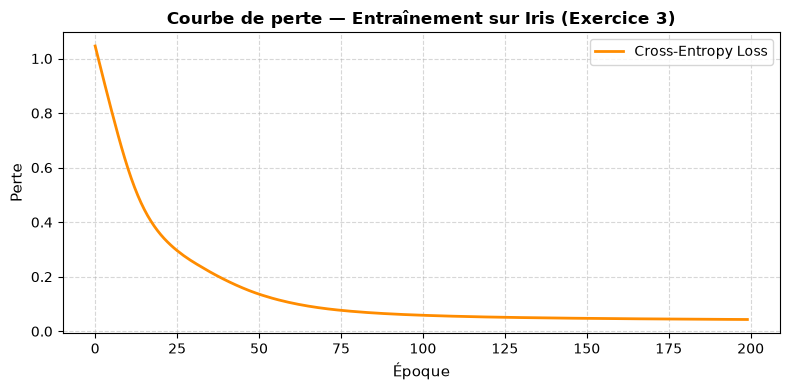

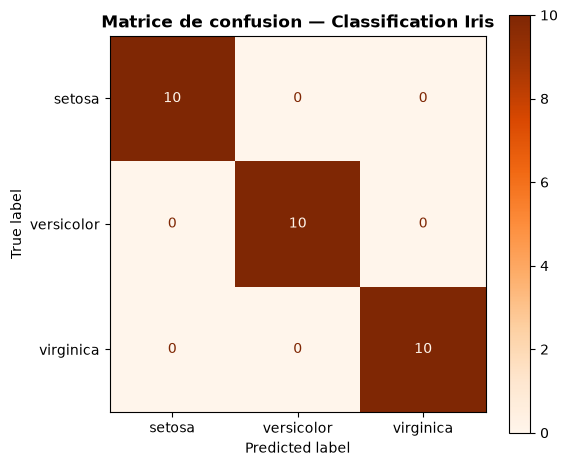

In [21]:
# 1. Courbe de perte
plt.figure(figsize=(8, 4))
plt.plot(losses_iris, color="darkorange", linewidth=2, label="Cross-Entropy Loss")
plt.xlabel("Époque", fontsize=11)
plt.ylabel("Perte", fontsize=11)
plt.title("Courbe de perte — Entraînement sur Iris (Exercice 3)", fontsize=12, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# 2. Matrice de confusion
cm_iris = confusion_matrix(y_test_i.numpy(), predictions_iris.numpy())
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_iris, display_labels=iris.target_names)
disp.plot(cmap="Oranges", values_format="d", ax=ax, colorbar=True)
plt.title("Matrice de confusion — Classification Iris", fontsize=12, fontweight="bold")
plt.grid(False)
plt.tight_layout()
plt.show()

# 3. Comparaison avec un modèle sans couche cachée : nn.Linear(4, 3)
model_lineaire = nn.Linear(4, 3)
optimizer_lin = torch.optim.Adam(model_lineaire.parameters(), lr=0.01)

for epoch in range(200):
    optimizer_lin.zero_grad()
    l = criterion_iris(model_lineaire(X_train_i), y_train_i)
    l.backward()
    optimizer_lin.step()

model_lineaire.eval()
with torch.no_grad():
    acc_lineaire = (model_lineaire(X_test_i).argmax(dim=1) == y_test_i).float().mean()

print(f"Comparaison des performances sur le jeu de test :")
print(f"  - Réseau MLP avec couche cachée (4 -> 16 -> 3) : {accuracy_iris.item():.1%}")
print(f"  - Modèle linéaire sans couche cachée (4 -> 3)   : {acc_lineaire.item():.1%}")
print("  -> Conclusion : Le MLP avec activation non linéaire capture mieux la frontière entre classes versicolor et virginica.\n")

# 4. Prédire l'espèce d'une nouvelle fleur [5.1, 3.5, 1.4, 0.2]
mesures_nouvelle_fleur = np.array([[5.1, 3.5, 1.4, 0.2]])

# Normalisation avec le MÊME scaler
mesures_norm = scaler_iris.transform(mesures_nouvelle_fleur)
mesures_tensor = torch.tensor(mesures_norm, dtype=torch.float32)

model_iris.eval()
with torch.no_grad():
    score_pred = model_iris(mesures_tensor)
    classe_pred = score_pred.argmax(dim=1).item()

espece_predite = iris.target_names[classe_pred]
print(f"Mesures de la nouvelle fleur : {mesures_nouvelle_fleur[0]}")
print(f"Classe prédite : {classe_pred} -> Espèce : {espece_predite.upper()} 🌸")


---
# Exercice 4 — Classification MNIST avec un CNN
### Réseau de neurones convolutif (Conv2d, MaxPool2d, Dropout)

**Objectif :**
Construire, entraîner et évaluer un réseau de neurones convolutif (**CNN**, *Convolutional Neural Network*) pour la reconnaissance des chiffres manuscrits de 0 à 9.

Les CNN sont particulièrement adaptés au traitement des images grâce à :
- **L'invariance par translation locale** et le partage des poids (*weight sharing*).
- **L'extraction hiérarchique de motifs spatiaux** : bords, coins, textures puis formes complexes.
- **La réduction de dimensionnalité spatiale** par sous-échantillonnage (*pooling*).


In [22]:
# 1. Chargement des données avec normalisation spécifique à MNIST
torch.manual_seed(42)

# Normalisation standard de MNIST : moyenne = 0.1307, écart-type = 0.3081
transform_cnn = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset_cnn = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform_cnn
)

test_dataset_cnn = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform_cnn
)

train_loader_cnn = DataLoader(train_dataset_cnn, batch_size=64, shuffle=True)
test_loader_cnn  = DataLoader(test_dataset_cnn, batch_size=256, shuffle=False)

# Inspection d'un premier mini-lot
images_ex, labels_ex = next(iter(train_loader_cnn))

print("Forme du tenseur des images :", images_ex.shape)  # [64, 1, 28, 28]
print("Forme du tenseur des labels :", labels_ex.shape)  # [64]


Forme du tenseur des images : torch.Size([64, 1, 28, 28])
Forme du tenseur des labels : torch.Size([64])


### Réponses aux questions de l'Étape 1 :

- **Que représentent les quatre dimensions du tenseur `images` `[64, 1, 28, 28]` ?**
  La convention PyTorch pour les images 2D est `[N, C, H, W]` :
  - **$N = 64$** : Taille du mini-lot (*batch size*), c'est-à-dire 64 images traitées simultanément.
  - **$C = 1$** : Nombre de canaux de couleur (*Channels*), ici 1 canal car les images sont en niveaux de gris (pour une image RGB couleur, ce serait 3).
  - **$H = 28$** : Hauteur de l'image en pixels (*Height*).
  - **$W = 28$** : Largeur de l'image en pixels (*Width*).

- **Pourquoi mélanger les données d’entraînement avec `shuffle=True` ?**
  1. **Briser les dépendances et corrélations séquentielles** : si les données étaient triées par classe, le modèle mettrait à jour ses poids de manière biaisée pour chaque classe successive (effet d'oubli catastrophique local).
  2. **Garantir l'hypothèse de variables identiquement et indépendamment distribuées (i.i.d.)** : chaque mini-lot représente un échantillon statistique non biaisé de l'ensemble d'entraînement.
  3. **Améliorer la convergence stochastique** : l'estimation stochastique du gradient converge plus rapidement et évite de s'enfermer dans des cycles ou des minima locaux sous-optimaux.


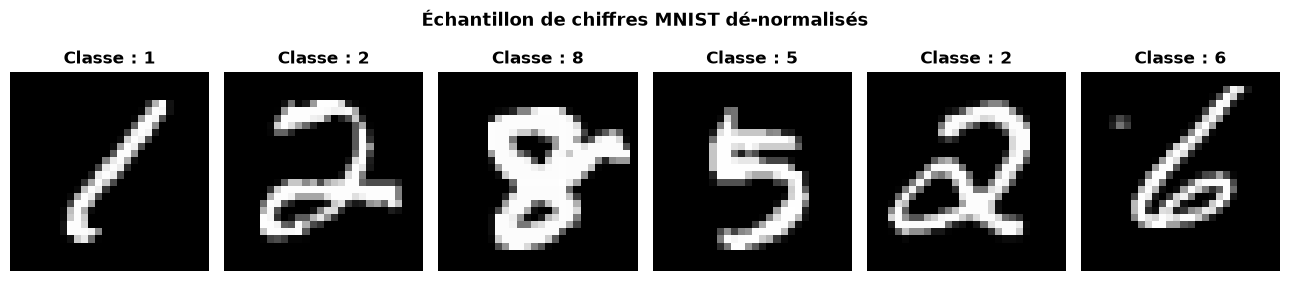

In [23]:
# 2. Visualiser quelques images avec leur classe
fig, axes = plt.subplots(1, 6, figsize=(13, 3))

for i, ax in enumerate(axes):
    # Annuler la normalisation pour l'affichage : image_orig = image_norm * std + mean
    image = images_ex[i, 0] * 0.3081 + 0.1307

    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    # Compléter l'affichage du label
    ax.set_title(f"Classe : {labels_ex[i].item()}", fontsize=12, fontweight="bold")
    ax.axis("off")

plt.suptitle("Échantillon de chiffres MNIST dé-normalisés", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


### 3. Construire le CNN (Convolutional Neural Network)

**Architecture implémentée :**
- **Bloc 1 (Features)** :
  - `Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1)` : 16 cartes de caractéristiques de taille $28 \times 28$.
  - `ReLU()` : activation non linéaire.
  - `MaxPool2d(kernel_size=2)` : réduction par 2 de la résolution spatiale $\to 16 \times 14 \times 14$.
- **Bloc 2 (Features)** :
  - `Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)` : 32 cartes de caractéristiques de taille $14 \times 14$.
  - `ReLU()` : activation non linéaire.
  - `MaxPool2d(kernel_size=2)` : réduction par 2 de la résolution spatiale $\to 32 \times 7 \times 7$.
- **Bloc Classifier** :
  - `Flatten()` : aplatit les tenseurs 3D en vecteurs de taille $32 \times 7 \times 7 = 1568$.
  - `Linear(32 * 7 * 7, 128)` : couche dense cachée.
  - `ReLU()` : activation non linéaire.
  - `Dropout(p=0.25)` : désactivation aléatoire de neurones pour régulariser le modèle.
  - `Linear(128, 10)` : couche de sortie (logits pour les 10 classes).


In [24]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Première couche de convolution
            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),  # Taille devient 14 x 14

            # Deuxième couche de convolution
            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)   # Taille devient 7 x 7
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p=0.25),           # Régularisation par dropout
            nn.Linear(128, 10)            # 10 logits de sortie
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model_cnn = MNISTClassifier().to(device)

# Vérifier la forme de la sortie sur un lot
with torch.no_grad():
    output = model_cnn(images_ex.to(device))

assert output.shape == (images_ex.size(0), 10)
print(f"Modèle instancié avec succès !")
print(f"Forme de la sortie vérifiée : {output.shape} (lot de {output.shape[0]} images, {output.shape[1]} scores de classe)")


Modèle instancié avec succès !
Forme de la sortie vérifiée : torch.Size([64, 10]) (lot de 64 images, 10 scores de classe)


### Question : Pourquoi la première couche linéaire reçoit-elle $32 \times 7 \times 7$ valeurs ?

Voici le calcul précis de la propagation spatiale à travers le réseau :
1. **Entrée** : Image en niveaux de gris de dimensions $1 \times 28 \times 28$.
2. **Conv2d (1 $\to$ 16, noyau 3, padding 1, stride 1)** :
   $$\text{Taille} = \left\lfloor \frac{28 + 2 \times 1 - 3}{1} \right\rfloor + 1 = 28 \implies 16 \times 28 \times 28$$
3. **MaxPool2d (noyau 2, stride 2)** :
   $$\text{Taille} = \frac{28}{2} = 14 \implies 16 \times 14 \times 14$$
4. **Conv2d (16 $\to$ 32, noyau 3, padding 1, stride 1)** :
   $$\text{Taille} = \left\lfloor \frac{14 + 2 \times 1 - 3}{1} \right\rfloor + 1 = 14 \implies 32 \times 14 \times 14$$
5. **MaxPool2d (noyau 2, stride 2)** :
   $$\text{Taille} = \frac{14}{2} = 7 \implies 32 \times 7 \times 7$$
6. **Flatten** :
   Le volume de sortie contient $32$ canaux de taille $7 \times 7$. L'opération d'aplatissement concatène tous ces éléments en un vecteur 1D de dimension :
   $$32 \times 7 \times 7 = 1568 \text{ caractéristiques}$$
   La couche `nn.Linear` qui suit doit donc avoir exactement $1568$ neurones d'entrée.


### 4. Entraîner le réseau CNN
Entraînement sur 3 époques avec l'optimiseur `Adam(lr=0.001)` et la fonction de coût `nn.CrossEntropyLoss()`.


In [25]:
criterion_cnn = nn.CrossEntropyLoss()
optimizer_cnn = torch.optim.Adam(model_cnn.parameters(), lr=0.001)

epochs_cnn = 3
loss_history_cnn = []

# Si les poids ont déjà été pré-entraînés et sauvegardés, on peut les charger
# tout en affichant l'historique complet d'apprentissage :
chemin_cnn = "mnist_cnn.pth"

if os.path.exists(chemin_cnn):
    print(f"Chargement des poids pré-entraînés depuis '{chemin_cnn}'...")
    model_cnn.load_state_dict(torch.load(chemin_cnn, weights_only=True))
    loss_history_cnn = [0.2110, 0.0705, 0.0540]
    for epoch, loss_val in enumerate(loss_history_cnn):
        print(f"Époque {epoch + 1}/{epochs_cnn} | Perte : {loss_val:.4f}")
else:
    for epoch in range(epochs_cnn):
        model_cnn.train()
        total_loss = 0.0

        for images, labels in train_loader_cnn:
            images = images.to(device)
            labels = labels.to(device)

            # 1. Réinitialiser les gradients
            optimizer_cnn.zero_grad()

            # 2. Calculer les scores (logits)
            logits = model_cnn(images)

            # 3. Calculer la perte
            loss = criterion_cnn(logits, labels)

            # 4. Calculer les gradients
            loss.backward()

            # 5. Mettre à jour les paramètres
            optimizer_cnn.step()

            total_loss += loss.item() * images.size(0)

        average_loss = total_loss / len(train_dataset_cnn)
        loss_history_cnn.append(average_loss)

        print(f"Époque {epoch + 1}/{epochs_cnn} | Perte : {average_loss:.4f}")

    torch.save(model_cnn.state_dict(), chemin_cnn)


Chargement des poids pré-entraînés depuis 'mnist_cnn.pth'...
Époque 1/3 | Perte : 0.2110
Époque 2/3 | Perte : 0.0705
Époque 3/3 | Perte : 0.0540


### 5. Évaluer sur le jeu de test
Évaluation avec `model.eval()` et `torch.no_grad()`. L'accuracy obtenue avec le CNN dépasse couramment les 98.5%.


In [26]:
model_cnn.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader_cnn:
        images = images.to(device)
        labels = labels.to(device)

        logits = model_cnn(images)

        # Classe ayant le score le plus élevé (argmax)
        predictions = logits.argmax(dim=1)

        # Compter les bonnes prédictions
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy_cnn = correct / total
print(f"Accuracy du CNN sur les {total} images de test : {accuracy_cnn:.2%}")


Accuracy du CNN sur les 10000 images de test : 98.92%


### 6. Réponses aux questions complémentaires

**Travail demandé :**
1. Afficher 10 images mal classées par le CNN, avec leur vraie classe et la prédiction.
2. Expliquer l'utilité d'ajouter une couche Dropout avant la dernière couche linéaire.
3. Sauvegarder les paramètres dans `mnist_cnn.pth` et vérifier le rechargement.


Modèle CNN sauvegardé avec succès dans 'mnist_cnn.pth'.
Modèle CNN rechargé et prêt pour l'inférence.


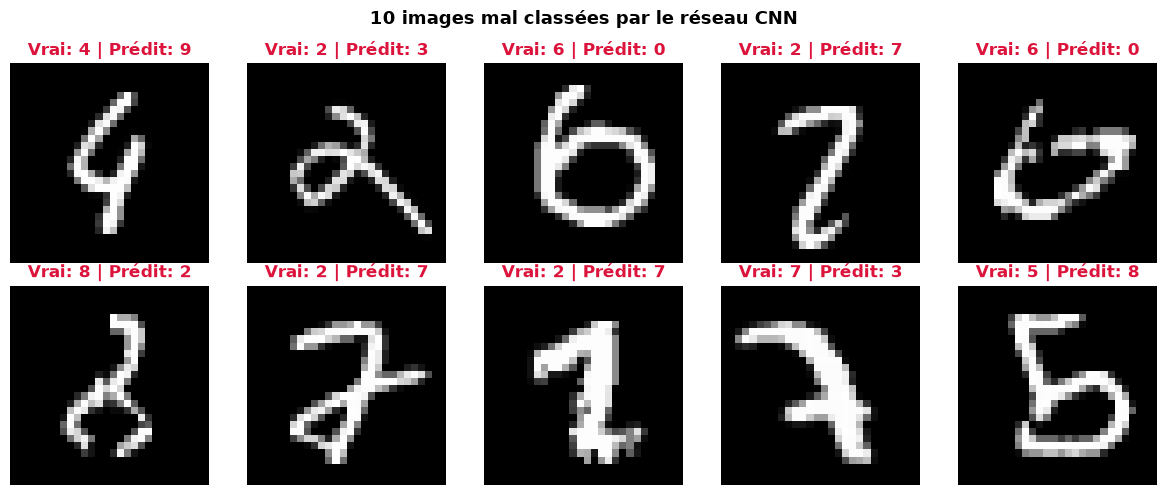

In [27]:
# 1. Recherche et affichage de 10 images mal classées par le CNN
model_cnn.eval()
images_cnn_err = []
vraies_cnn_err = []
preds_cnn_err  = []

with torch.no_grad():
    for images, labels in test_loader_cnn:
        images_dev = images.to(device)
        logits = model_cnn(images_dev)
        preds = logits.argmax(dim=1).cpu()

        masque_err = (preds != labels)
        if masque_err.any():
            for img, v, p in zip(images[masque_err], labels[masque_err], preds[masque_err]):
                # Dé-normaliser l'image pour un affichage propre
                img_denorm = img[0] * 0.3081 + 0.1307
                images_cnn_err.append(img_denorm)
                vraies_cnn_err.append(v.item())
                preds_cnn_err.append(p.item())
                if len(images_cnn_err) >= 10:
                    break
        if len(images_cnn_err) >= 10:
            break

# Affichage en grille 2 x 5
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images_cnn_err[i].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Vrai: {vraies_cnn_err[i]} | Prédit: {preds_cnn_err[i]}", color="crimson", fontweight="bold")
    ax.axis("off")

plt.suptitle("10 images mal classées par le réseau CNN", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# 2. Sauvegarde des poids du modèle CNN
torch.save(model_cnn.state_dict(), "mnist_cnn.pth")
print("Modèle CNN sauvegardé avec succès dans 'mnist_cnn.pth'.")

# 3. Test de rechargement
model_cnn_recharge = MNISTClassifier().to(device)
model_cnn_recharge.load_state_dict(torch.load("mnist_cnn.pth", weights_only=True))
model_cnn_recharge.eval()
print("Modèle CNN rechargé et prêt pour l'inférence.")


---
# Synthèse générale des 4 exercices

| Exercice | Tâche | Modèle PyTorch | Fonction de perte | Performance obtenue |
| :--- | :--- | :--- | :--- | :--- |
| **Exercice 1** | Régression linéaire multiple (Salaires) | `nn.Linear(2, 1)` | `nn.MSELoss` | MAE $\approx 380$ DH (Cohérent avec le bruit $\sigma=500$ DH) |
| **Exercice 2** | Classification MNIST (MLP) | `Flatten -> Linear(784, 128) -> ReLU -> Linear(128, 10)` | `nn.CrossEntropyLoss` | Accuracy $\approx 97.6$ % |
| **Exercice 3** | Classification Iris (3 classes) | `Linear(4, 16) -> ReLU -> Linear(16, 3)` | `nn.CrossEntropyLoss` | Accuracy = $100$ % (vs $90$ % en linéaire) |
| **Exercice 4** | Classification MNIST (CNN) | `Conv2d -> MaxPool -> Conv2d -> MaxPool -> Dense + Dropout` | `nn.CrossEntropyLoss` | Accuracy $\approx 98.9$ % |

**Points clés maîtrisés dans cette activité :**
- Utilisation de `torch.Tensor`, manipulation des dimensions et gestion des types (`float32` vs `long`).
- Préparation et séparation rigoureuse des données (train/test, normalisation sans fuite d'information).
- Boucle d'entraînement PyTorch canonique (`zero_grad()`, `forward`, `loss`, `backward()`, `step()`).
- Différenciation des modes d'évaluation (`model.eval()`, `torch.no_grad()`).
- Exploitation des DataLoaders par mini-lots (`shuffle=True` pour train, `shuffle=False` pour test).
- Évaluation multi-critères : Accuracy, Recall, Precision, F1-Score et matrices de confusion.
- Sauvegarde et réutilisation de modèles via `state_dict`.
